In [78]:
import sys
path='/home/tomas/Ulmer-Berechnung/alps2qutipplus-april/alps2qutipplus-main/'

sys.path.insert(1, path) 

In [79]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qutip
import scipy.linalg as linalg
import time

from alpsqutip import (build_system, list_models_in_alps_xml,
                       list_geometries_in_alps_xml, graph_from_alps_xml,
                       model_from_alps_xml,
                       restricted_maxent_toolkit as me)

from alpsqutip.operators.states.utils import safe_exp_and_normalize ## function used to safely and robustly map K-states to states

from alpsqutip.operators.states.meanfield.projections import (one_body_from_qutip_operator, 
                                                  project_operator_to_m_body, 
                                                             project_qutip_operator_to_m_body,
                                                             project_to_n_body_operator,
                                                             project_qutip_operator_as_n_body_operator,
                                                             project_product_operator_as_n_body_operator)

from alpsqutip.operators import (
    ScalarOperator,
    LocalOperator,
    OneBodyOperator,
    Operator,
    ProductOperator,
    ScalarOperator,
    SumOperator,
    QutipOperator
)

from alpsqutip.scalarprod import gram_matrix, fetch_covar_scalar_product, orthogonalize_basis
from alpsqutip.operators.states.gibbs import GibbsDensityOperator, GibbsProductDensityOperator

In [80]:
params={}

params['size']=5
params['Jx']=1.; params['Jy'] = .75*params['Jx']; params['Jz']=1.05*params['Jx']

from scipy.optimize import root, fsolve
Ffactor=np.real(max(np.roots(np.poly1d([1, 0, -(params['Jx']*params['Jy']+params['Jx']*params['Jy']+params['Jy']*params['Jz']), 
                           -2*params['Jx']*params['Jy']*params['Jz']]))))
chi_y=fsolve(lambda x,y: x*np.arcsinh(x)-np.sqrt(x**2+1)-y, 1e-1, args=(0))[0]
vLR=4*Ffactor*chi_y

In [81]:
system=build_system(geometry_name= "open chain lattice",model_name="spin", 
                    L=params['size'], J=1)

sites=[s for s in system.sites]
sx_ops=[system.site_operator("Sx", '1[' + str(a) + ']') for a in range(len(system.sites))]
sy_ops=[system.site_operator("Sy", '1[' + str(a) + ']') for a in range(len(system.sites))]
sz_ops=[system.site_operator("Sz", '1[' + str(a) + ']') for a in range(len(system.sites))]

Sz = system.global_operator("Sz")
H = (
    params['Jx'] * sum(sx_ops[i] * sx_ops[i+1] for i in range(len(sites)-1)) +
    params['Jy'] * sum(sy_ops[i] * sy_ops[i+1] for i in range(len(sites)-1)) +
    params['Jz'] * sum(sz_ops[i] * sz_ops[i+1] for i in range(len(sites)-1))
)

idop = [system.site_operator('identity@1[' + str(a) + ']') for a in range(len(system.sites))]
idop = ScalarOperator(1,system)

loading model spin  over graph open chain lattice


In [82]:
HBB0=[idop, 
      system.site_operator('Sz', '1[0]'), 
      system.site_operator('Sz', '1[1]'), 
      system.site_operator('Sz', '1[2]')]


phi0 = np.array([.0, -.35, -.25, 
                 .4])

K0 = me.k_state_from_phi_basis(phi0, HBB0)
sigma0 = GibbsProductDensityOperator(K0)
phi0[0] = sum(sigma0.free_energies.values())

timespan=np.linspace(.0, 1200.1/vLR,100)
obs_SzA = sum(sz for sz in sz_ops)
[(sigma0 * op).tr() for op in sz_ops] 

[0.0866175789173301, 0.0621765008857981, -0.09868766011245195, 0.0, 0.0]

In [83]:
sigma0

In [84]:
sigma0.to_qutip()

Quantum object: dims = [[2, 2, 2, 2, 2], [2, 2, 2, 2, 2]], shape = (32, 32), type = oper, isherm = True
Qobj data =
[[0.0270889  0.         0.         ... 0.         0.         0.        ]
 [0.         0.0270889  0.         ... 0.         0.         0.        ]
 [0.         0.         0.0270889  ... 0.         0.         0.        ]
 ...
 [0.         0.         0.         ... 0.03308646 0.         0.        ]
 [0.         0.         0.         ... 0.         0.03308646 0.        ]
 [0.         0.         0.         ... 0.         0.         0.03308646]]

In [85]:
## exact dynamics
exact_K_at_timet=qutip.mesolve(H=H.to_qutip(), rho0=K0.to_qutip(), tlist=timespan)
exact_rho_at_timet=[safe_exp_and_normalize(-K_at_timeti)[0] for K_at_timeti in exact_K_at_timet.states]

evs_obs_ex=[qutip.expect(rho_at_timeti, obs_SzA.to_qutip()) for rho_at_timeti in exact_rho_at_timet]

In [86]:
simulations={}

In [87]:
simulations[1] = {
    "parms":{
    "chosen_depth": 12,
    "m0": 2,
    "eps": 1e-3,
    },
  "saved_cut_times_index_ell":[0],
   "no_acts_ell" : [0],
    "local_bound_error_ell":[],
    "spectral_norm_Hij_tensor_ell":[],
    "instantaneous_w_errors":[],
} 

current_simulation = simulations[1]
current_simulation_parms = current_simulation["parms"]
chosen_depth = current_simulation_parms["chosen_depth"]
eps_tol = current_simulation_parms["eps"]
m0 = current_simulation_parms["m0"]

In [88]:
# phi0_proj_act_MF = []; local_bound_error_ell=[]
local_bound_error_ell = []
simulations[1]["evs"] = [(sigma0.to_qutip()* obs_SzA.to_qutip()).tr()]

sp_local=fetch_covar_scalar_product(sigma=sigma0); local_t_value=.0

HBB_ell_act = me.build_hierarchical_basis(generator=H.to_qutip_operator(),
                                          seed_op=K0.to_qutip_operator(),
                                          deep=chosen_depth,
                                          to_qutip_operator=True)

HBB_ell_act = [op.to_qutip_operator() for op in HBB_ell_act]

orth_basis_act = orthogonalize_basis(basis=HBB_ell_act,
                                        sp = sp_local)

Hij_tensor_act, w_errors = me.fn_hij_tensor_with_errors(generator=H.to_qutip_operator(), 
                                                        basis=orth_basis_act,
                                                        sp=sp_local)

phi0_proj_act = [sp_local(K0, op) for op in orth_basis_act]
sigma_at_timet = [GibbsProductDensityOperator(K0)]  
sigma_act = sigma_at_timet[0]

for t in timespan[1:]:
    start=time.time()
    phi_local=np.real(linalg.expm(Hij_tensor_act * (t - local_t_value)) @ phi0_proj_act)  
    
    print(f"A. phi-local, {time.time() - start:.2f}s");   start=time.time();
    
    K_local=me.k_state_from_phi_basis(phi=phi_local,
                                        basis=orth_basis_act) ### i put the minus in order to get a plusK
    
    print(f"B. K-local, {time.time() - start:.2f}s");   start=time.time();
        
    simulations[1]["evs"].append((GibbsDensityOperator(K_local)*obs_SzA).tr()) ### the minus is here
    
    print(f"C. obs-calc, {time.time() - start:.2f}s");   start=time.time();
    
    local_bound_error_ell.append(me.m_th_partial_sum(phi=phi_local, m=2)
                                 / me.m_th_partial_sum(phi=phi_local, m=0))
    
    if abs(local_bound_error_ell[-1]) >= eps_tol:
        
        local_t_value = t ; start = time.time()
        
        print("a. start t=", list(timespan).index(t))
        if True:
            K_act=project_to_n_body_operator(operator=K_local.as_sum_of_products(),
                                         sigma=sigma_act, 
                                         nmax=1)
            sigma_act=GibbsProductDensityOperator(K_act)
        
        end = time.time(); print(f"b. Kact-m1proj, {end - start:.3f}s")
        
        start = time.time()
        
        sp_local = fetch_covar_scalar_product(sigma=sigma_act)  
        HBB_ell_act = (me.build_hierarchical_basis(generator=H.to_qutip_operator(),
                                                            seed_op=K_local.to_qutip_operator(), 
                                                            deep=chosen_depth,
                                                            to_qutip_operator=False)[1:] 
                            + [K_act.to_qutip_operator()])
        
        HBB_ell_act = [op.simplify() for op in HBB_ell_act]
        
        end = time.time(); print(f"c. HBact constr., {end - start:.6f}s")
        
        start = time.time()
        
        HBB_ell_act= ([project_qutip_operator_as_n_body_operator
                                              (operator = op.as_sum_of_products(), 
                                               nmax=m0,
                                               sigma=sigma_act).to_qutip_operator()
                      for op in HBB_ell_act][0:])
        
        end = time.time(); print(f"d. HBact proj, {end - start:.6f}s")
        orth_basis_act = orthogonalize_basis(basis=[K_local.to_qutip_operator()]+HBB_ell_act,
                                             sp=sp_local)  
        
        start = time.time()
        
        Hij_tensor_act, w_errors = me.fn_hij_tensor_with_errors(generator=H.to_qutip_operator(), 
                                                                basis=orth_basis_act,
                                                                sp=sp_local)
        
        end = time.time(); print(f"e. Hijact constr, {end - start:.6f}s")
        print(linalg.norm(Hij_tensor_act))
        
        phi0_proj_act = np.array([np.real(sp_local(K_local, op)) for op in orth_basis_act] ).round(10)
        new_K_local=sum(phi0a * opa for phi0a, opa in zip(phi0_proj_act, orth_basis_act))### same here
        print("Fita: Check", linalg.norm((new_K_local - K_local).to_qutip()))
    else:
        # If error is below the threshold, retain the current basis and 
        pass

A. phi-local, 0.00s
B. K-local, 0.03s
C. obs-calc, 0.10s
A. phi-local, 0.01s
B. K-local, 0.15s
C. obs-calc, 0.12s
A. phi-local, 0.00s
B. K-local, 0.24s
C. obs-calc, 0.15s
a. start t= 3
b. Kact-m1proj, 1.810s
c. HBact constr., 0.009571s
d. HBact proj, 18.216444s
e. Hijact constr, 0.657439s
1.9953538766019174
Fita: Check 1.6664356446551995e-10
A. phi-local, 0.00s
B. K-local, 0.16s
C. obs-calc, 0.13s
a. start t= 4
b. Kact-m1proj, 1.677s
c. HBact constr., 0.009937s
d. HBact proj, 20.949516s
e. Hijact constr, 0.601597s
1.9888487945783553
Fita: Check 0.0
A. phi-local, 0.00s
B. K-local, 0.16s
C. obs-calc, 0.16s
a. start t= 5
b. Kact-m1proj, 1.722s
c. HBact constr., 0.009721s
d. HBact proj, 18.672182s
e. Hijact constr, 0.600827s
1.7968467802788604
Fita: Check 0.0
A. phi-local, 0.01s
B. K-local, 0.17s
C. obs-calc, 0.16s
A. phi-local, 0.00s
B. K-local, 0.16s
C. obs-calc, 0.17s
a. start t= 7
b. Kact-m1proj, 1.643s
c. HBact constr., 0.009532s
d. HBact proj, 19.885815s
e. Hijact constr, 0.598490s
2

d. HBact proj, 21.494868s
e. Hijact constr, 0.638110s
2.1594751909224894
Fita: Check 0.0
A. phi-local, 0.00s
B. K-local, 0.16s
C. obs-calc, 0.16s
a. start t= 46
b. Kact-m1proj, 1.686s
c. HBact constr., 0.011818s
d. HBact proj, 21.061462s
e. Hijact constr, 0.601986s
2.1719315803640344
Fita: Check 0.0
A. phi-local, 0.00s
B. K-local, 0.17s
C. obs-calc, 0.16s
a. start t= 47
b. Kact-m1proj, 1.701s
c. HBact constr., 0.237118s
d. HBact proj, 20.914138s
e. Hijact constr, 0.602118s
2.2352406684721333
Fita: Check 0.0
A. phi-local, 0.00s
B. K-local, 0.16s
C. obs-calc, 0.17s
A. phi-local, 0.00s
B. K-local, 0.16s
C. obs-calc, 0.14s
a. start t= 49
b. Kact-m1proj, 1.714s
c. HBact constr., 0.009522s
d. HBact proj, 21.079247s
e. Hijact constr, 0.601183s
2.09663014737962
Fita: Check 0.0
A. phi-local, 0.00s
B. K-local, 0.17s
C. obs-calc, 0.24s
a. start t= 50
b. Kact-m1proj, 1.673s
c. HBact constr., 0.041969s
d. HBact proj, 20.847269s
e. Hijact constr, 0.600568s
2.1475209391916827
Fita: Check 0.0
A. phi-l

B. K-local, 0.18s
C. obs-calc, 0.16s
a. start t= 93
b. Kact-m1proj, 1.783s
c. HBact constr., 0.009487s
d. HBact proj, 21.184680s
e. Hijact constr, 0.605428s
2.232441004232132
Fita: Check 0.0
A. phi-local, 0.00s
B. K-local, 0.16s
C. obs-calc, 0.14s
A. phi-local, 0.00s
B. K-local, 0.16s
C. obs-calc, 0.15s
a. start t= 95
b. Kact-m1proj, 2.176s
c. HBact constr., 0.009530s
d. HBact proj, 20.800935s
e. Hijact constr, 0.613070s
2.142711327473301
Fita: Check 0.0
A. phi-local, 0.00s
B. K-local, 0.16s
C. obs-calc, 0.13s
A. phi-local, 0.00s
B. K-local, 0.17s
C. obs-calc, 0.16s
A. phi-local, 0.00s
B. K-local, 0.21s
C. obs-calc, 0.14s
a. start t= 98
b. Kact-m1proj, 1.724s
c. HBact constr., 0.009587s
d. HBact proj, 20.858878s
e. Hijact constr, 0.598428s
2.0910278439316397
Fita: Check 0.0
A. phi-local, 0.00s
B. K-local, 0.16s
C. obs-calc, 0.17s
a. start t= 99
b. Kact-m1proj, 1.694s
c. HBact constr., 0.009578s
d. HBact proj, 20.979412s
e. Hijact constr, 1.066745s
2.192266791645225
Fita: Check 0.0


In [97]:
simulations[2] = {
    "parms":{
    "chosen_depth": 12,
    "m0": 2,
    "eps": 1e-3,
    },
  "saved_cut_times_index_ell":[0],
   "no_acts_ell" : [0],
    "local_bound_error_ell":[],
    "spectral_norm_Hij_tensor_ell":[],
    "instantaneous_w_errors":[],
} 

current_simulation = simulations[2]
current_simulation_parms = current_simulation["parms"]
chosen_depth = current_simulation_parms["chosen_depth"]
eps_tol = current_simulation_parms["eps"]
m0 = current_simulation_parms["m0"]

In [98]:
# phi0_proj_act_MF = []; local_bound_error_ell=[]
local_bound_error_ell = []
simulations[2]["evs"] = [(sigma0.to_qutip()* obs_SzA.to_qutip()).tr()]

sp_local=fetch_covar_scalar_product(sigma=sigma0); local_t_value=.0

HBB_ell_act = me.build_hierarchical_basis(generator=H.to_qutip_operator(),
                                          seed_op=K0.to_qutip_operator(),
                                          deep=chosen_depth,
                                          to_qutip_operator=True)

HBB_ell_act = [op.simplify().to_qutip_operator() for op in HBB_ell_act]

orth_basis_act = orthogonalize_basis(basis=HBB_ell_act,
                                        sp = sp_local)

Hij_tensor_act, w_errors = me.fn_hij_tensor_with_errors(generator=H.to_qutip_operator(), 
                                                        basis=orth_basis_act,
                                                        sp=sp_local)

phi0_proj_act = [sp_local(K0, op) for op in orth_basis_act]
sigma_act = sigma_at_timet[0]

for t in timespan[1:]:
    
    start = time.time()
    phi_local=np.real(linalg.expm(Hij_tensor_act * (t - local_t_value)) @ phi0_proj_act)  
    
    print(f"A. phi-local, {time.time() - start:.2f}s");   start=time.time();
    
    K_local=me.k_state_from_phi_basis(phi=phi_local,
                                        basis=orth_basis_act) ### i put the minus in order to get a plusK
    
    
    print(f"B. K-local, {time.time() - start:.2f}s");   start=time.time();
    
    simulations[2]["evs"].append((GibbsDensityOperator(K_local.to_qutip_operator())
                                  *obs_SzA.to_qutip_operator()).tr()) ### the minus is here
    
    print(f"C. obs-calc, {time.time() - start:.2f}s");   start=time.time();
        
    local_bound_error_ell.append(me.m_th_partial_sum(phi=phi_local, m=2)
                                 / me.m_th_partial_sum(phi=phi_local, m=0))
    
    if abs(local_bound_error_ell[-1]) >= eps_tol:
        
        local_t_value = t ; start = time.time()
        
        print("___a. start act t=", list(timespan).index(t))
        
        start = time.time()
        
        K_proj_m0=project_to_n_body_operator(operator=K_local.as_sum_of_products(),
                                         sigma=sigma_act, 
                                         nmax=m0).simplify()
        
        end = time.time(); print(f"___b. Kact-m0proj, {end - start:.2f}s")
        
        if True:
            K_act=project_to_n_body_operator(operator=K_proj_m0.as_sum_of_products(),
                                         sigma=sigma_act, 
                                         nmax=1).simplify()
            sigma_act=GibbsProductDensityOperator(K_act)  
            
            
        end = time.time(); print(f"___c. Kact-m1proj, {end - start:.2f}s")
        
        sp_local = fetch_covar_scalar_product(sigma=sigma_act)  
        
        HBB_ell_act = me.build_hierarchical_basis(generator=H.to_qutip_operator(),
                                                            seed_op=K_proj_m0.to_qutip_operator(), 
                                                            deep=chosen_depth,
                                                            to_qutip_operator=False)[1:]
        
        HBB_ell_act = [op.simplify() for op in HBB_ell_act]
        
        end = time.time(); print(f"___d. HBact proj, {end - start:.2f}s")
        orth_basis_act = orthogonalize_basis(basis=[K_local.to_qutip_operator()]+HBB_ell_act,
                                             sp=sp_local)  
        
        start = time.time()
        
        Hij_tensor_act, w_errors = me.fn_hij_tensor_with_errors(generator=H.to_qutip_operator(), 
                                                                basis=orth_basis_act,
                                                                sp=sp_local)
        
        end = time.time(); print(f"___e. Hijact constr, {end - start:.2f}s")
        
        phi0_proj_act = np.array([np.real(sp_local(K_local, op)) for op in orth_basis_act] ).round(10)
        new_K_local=sum(phi0a * opa for phi0a, opa in zip(phi0_proj_act, orth_basis_act))### same here
        print("Fita: Check", linalg.norm((new_K_local - K_local).to_qutip()))
    else:
        # If error is below the threshold, retain the current basis and 
        pass

A. phi-local, 0.00s
B. K-local, 0.18s
C. obs-calc, 0.17s
A. phi-local, 0.00s
B. K-local, 0.17s
C. obs-calc, 0.17s
A. phi-local, 0.00s
B. K-local, 0.18s
C. obs-calc, 0.13s
___a. start act t= 3
___b. Kact-m0proj, 3.05s
___c. Kact-m1proj, 3.21s
___d. HBact proj, 3.23s
___e. Hijact constr, 0.73s
Fita: Check 1.6664356446551995e-10
A. phi-local, 0.00s
B. K-local, 0.16s
C. obs-calc, 0.16s
___a. start act t= 4
___b. Kact-m0proj, 3.05s
___c. Kact-m1proj, 3.14s
___d. HBact proj, 3.15s
___e. Hijact constr, 0.48s
Fita: Check 0.0
A. phi-local, 0.00s
B. K-local, 0.17s
C. obs-calc, 0.13s
___a. start act t= 5
___b. Kact-m0proj, 2.04s
___c. Kact-m1proj, 2.14s
___d. HBact proj, 2.15s
___e. Hijact constr, 0.57s
Fita: Check 0.0
A. phi-local, 0.00s
B. K-local, 0.21s
C. obs-calc, 0.14s
___a. start act t= 6
___b. Kact-m0proj, 2.12s
___c. Kact-m1proj, 2.21s
___d. HBact proj, 2.23s
___e. Hijact constr, 0.57s
Fita: Check 1.4482056089436762e-10
A. phi-local, 0.00s
B. K-local, 0.16s
C. obs-calc, 0.12s
___a. start

B. K-local, 0.16s
C. obs-calc, 0.17s
___a. start act t= 43
___b. Kact-m0proj, 2.19s
___c. Kact-m1proj, 2.28s
___d. HBact proj, 2.30s
___e. Hijact constr, 0.55s
Fita: Check 0.0
A. phi-local, 0.00s
B. K-local, 0.21s
C. obs-calc, 0.19s
A. phi-local, 0.00s
B. K-local, 0.21s
C. obs-calc, 0.13s
___a. start act t= 45
___b. Kact-m0proj, 2.18s
___c. Kact-m1proj, 2.27s
___d. HBact proj, 2.28s
___e. Hijact constr, 0.55s
Fita: Check 1.29639515059034e-10
A. phi-local, 0.00s
B. K-local, 0.17s
C. obs-calc, 0.15s
___a. start act t= 46
___b. Kact-m0proj, 2.22s
___c. Kact-m1proj, 2.32s
___d. HBact proj, 2.33s
___e. Hijact constr, 0.53s
Fita: Check 0.0
A. phi-local, 0.00s
B. K-local, 0.17s
C. obs-calc, 0.15s
___a. start act t= 47
___b. Kact-m0proj, 2.24s
___c. Kact-m1proj, 2.33s
___d. HBact proj, 2.34s
___e. Hijact constr, 0.51s
Fita: Check 3.8991930999330555e-11
A. phi-local, 0.00s
B. K-local, 0.17s
C. obs-calc, 0.18s
___a. start act t= 48
___b. Kact-m0proj, 2.18s
___c. Kact-m1proj, 2.27s
___d. HBact pr

___e. Hijact constr, 0.52s
Fita: Check 0.0
A. phi-local, 0.00s
B. K-local, 0.16s
C. obs-calc, 0.16s
___a. start act t= 87
___b. Kact-m0proj, 2.33s
___c. Kact-m1proj, 2.43s
___d. HBact proj, 2.44s
___e. Hijact constr, 0.50s
Fita: Check 0.0
A. phi-local, 0.00s
B. K-local, 0.16s
C. obs-calc, 0.18s
___a. start act t= 88
___b. Kact-m0proj, 2.31s
___c. Kact-m1proj, 2.41s
___d. HBact proj, 2.42s
___e. Hijact constr, 0.51s
Fita: Check 0.0
A. phi-local, 0.00s
B. K-local, 0.17s
C. obs-calc, 0.17s
___a. start act t= 89
___b. Kact-m0proj, 2.36s
___c. Kact-m1proj, 2.45s
___d. HBact proj, 2.47s
___e. Hijact constr, 0.51s
Fita: Check 2.461881017627268e-10
A. phi-local, 0.01s
B. K-local, 0.22s
C. obs-calc, 0.15s
___a. start act t= 90
___b. Kact-m0proj, 2.40s
___c. Kact-m1proj, 2.50s
___d. HBact proj, 2.53s
___e. Hijact constr, 0.74s
Fita: Check 4.054118893501005e-11
A. phi-local, 0.00s
B. K-local, 0.21s
C. obs-calc, 0.17s
___a. start act t= 91
___b. Kact-m0proj, 2.32s
___c. Kact-m1proj, 2.41s
___d. HB

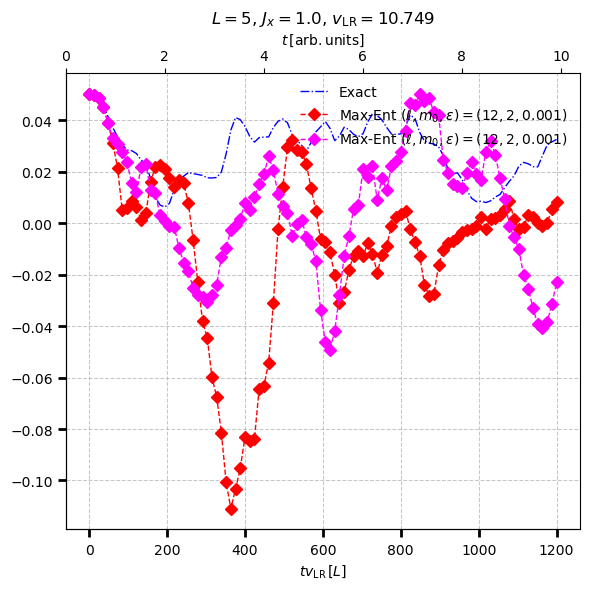

In [100]:
import matplotlib.pyplot as plt

# Création de la figure et des axes
fig, ax = plt.subplots(figsize=(6, 6))

n = 1

# Tracé de la courbe exacte
ax.plot(timespan*vLR, evs_obs_ex, label='Exact', color="blue", linestyle='dashdot', linewidth=1)

# Récupération des paramètres pour formater dynamiquement le label
l = simulations[2]["parms"]["chosen_depth"]
m0 = simulations[2]["parms"]["m0"]
eps = simulations[2]["parms"]["eps"]

label_sim1 = fr'Max-Ent $(\ell, m_0, \epsilon) = ({l}, {m0}, {eps})$'


# Tracé de la simulation 1


ax.plot(timespan*vLR, simulations[1]["evs"], 
        label=label_sim1, 
        color='red', linestyle='--', marker='D', linewidth=1)

ax.plot(timespan*vLR, simulations[2]["evs"], 
        label=label_sim1, 
        color='magenta', linestyle='--', marker='D', linewidth=1)

# Bordures uniquement à gauche et en bas (style minimaliste)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Personnalisation des ticks
ax.tick_params(direction='out', length=6, width=2, which='major', grid_alpha=0.6)
ax.grid(True, which='major', linestyle='--', linewidth=0.75, alpha=0.7)

ax.legend(frameon=False, loc='upper right')

# Axe secondaire
ax1 = ax.twiny()
ax1.set_xlim(timespan[0]/vLR, timespan[-1]/vLR)

# Étiquettes des axes
ax.set_xlabel(r'$t v_{\rm LR} \, [L]$')
ax1.set_xlabel(r'$t \, [{\rm arb. units}]$')

# Titre formaté avec LaTeX
plt.title(r'$L={}$, $J_x={}$, $v_{{\rm LR}}={}$'.format(
    params['size'], 
    round(params['Jx'], 3), 
    round(vLR, 3)
))

# Ajustement final
plt.tight_layout()


In [95]:
qutip.Qobj(Hij_tensor_act).tidyup(1e-4)

Quantum object: dims = [[12], [12]], shape = (12, 12), type = oper, isherm = False
Qobj data =
[[ 7.80814862e-04 -2.27518099e-01  2.33467144e-02  1.39461564e-01
  -7.15918818e-02 -1.04217560e-01  2.75131828e-02 -4.32849721e-03
  -9.21563836e-02  3.83295682e-02 -3.65660280e-02 -1.15650536e-01]
 [ 2.29970893e-01 -4.94980987e-03 -2.35623311e+00  6.57566275e-04
   8.09273984e-03  1.41329752e-02  9.49222225e-03  0.00000000e+00
   4.98014562e-03 -2.35807838e-03  5.12815667e-03  1.13913919e-03]
 [-1.58037922e-02  2.35394567e+00 -5.48729842e-03 -1.32472736e+00
  -1.09875059e-02 -1.69305059e-02  1.58127236e-02  1.07496350e-03
  -9.49346085e-03  3.07961816e-03 -5.08745332e-03 -1.04480558e-02]
 [-1.56909221e-01  4.29987058e-03  1.31609910e+00  2.36708168e-03
  -1.63515403e+00 -2.40700107e-03 -4.05359700e-03  1.62363639e-02
   5.63036684e-03 -5.02128674e-03  5.04854102e-03  8.41542526e-04]
 [ 6.43411470e-02 -1.76317621e-03  6.22039712e-03  1.63646058e+00
   3.15473464e-03 -9.46298451e-01 -1.540458

In [96]:
phi0_proj_act

array([ 0.33217849,  0.        ,  0.        , -0.        , -0.        ,
        0.        , -0.        ,  0.        , -0.        ,  0.        ,
        0.        ,  0.        ])